In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots

## RAMZI MODEL

RAMZI é composto por um micro-ring resonator (MRR) e MZI em série. Podemos escrever a dinâmica do (MRR) com a amplitude de luz, **$a$**, e a densidade de portadores **$N_c$**:

\begin{equation}
\frac{da}{dt} = - \left(j\Delta\omega + \gamma_L\right)a - j\eta_{fc}N_{c}a - j\mu\sqrt{P_{in}}
\end{equation}

\begin{equation}
\frac{dN_c}{dt} + \frac{N_c}{\tau_{fc}} = \xi |a|^4
\end{equation}




In [127]:
class MRR:
    def __init__(self, delta_w, gamma_l, eta_fc, mu, tau_fc, xi, dt=1e-12):
        self.delta_w = delta_w
        self.gamma_l = gamma_l
        self.eta_fc = eta_fc
        self.mu = mu
        self.tau_fc = tau_fc
        self.xi = xi
        self.dt = dt

    def forward(self, Pin, delta_phi=0.0, steps=2500):
        a = 0 + 0j
        Nc = 0.0
        sqrt_Pin = np.sqrt(Pin)

        for _ in range(steps):
            da_dt = (
                -(1j * self.delta_w + self.gamma_l) * a
                - 1j * self.eta_fc * Nc * a
                - 1j * self.mu * sqrt_Pin
            )
            dNc_dt = self.xi * (np.abs(a)**4) - (Nc / self.tau_fc)

            a += da_dt * self.dt
            Nc += dNc_dt * self.dt

        E1 = a / np.sqrt(2)
        E2 = a * np.exp(1j * delta_phi) / np.sqrt(2)
        E_out = (E1 + E2) / np.sqrt(2)
        
        return np.abs(E_out)**2

# class MZI:
#     def __init__(self, delta_phi=0):
#         self.delta_phi = delta_phi

#     def forward(self, Ein):
#         E1 = Ein / np.sqrt(2)
#         E2 = Ein * np.exp(1j * self.delta_phi) / np.sqrt(2)
#         return (E1 + E2) / np.sqrt(2)

# class RAMZI:
#     def __init__(self, delta_w=0, gamma_l=0.05, eta_fc=1, mu=0.5, tau_fc=50, xi=1e-2, delta_phi=0):
#         self.mrr = MRR(delta_w, gamma_l, eta_fc, mu, tau_fc, xi)
#         self.mzi = MZI(delta_phi)

#     def forward(self, Pin, steps=3000):
#         a_regime, _ = self.mrr.simulate(Pin, steps)
#         E_out = self.mzi.forward(a_regime)
#         return np.abs(E_out)**2

# class SOA:
#     def __init__(self, gain=10):
#         self.gain = gain

#     def forward(self, Pin):
#         return self.gain * Pin

# class DRAMZI:
#     def __init__(self, ramzi1, ramzi2, gain=10):
#         self.r1 = ramzi1
#         self.soa = SOA(gain)
#         self.r2 = ramzi2

#     def forward(self, Pin, steps=3000):
#         P1 = self.r1.forward(Pin, steps)
#         P_amplified = self.soa.forward(P1)
#         P2 = self.r2.forward(P_amplified, steps)
#         return P2

mrr1 = MRR(delta_w=0, gamma_l=0.05, eta_fc=1, mu=0.5, tau_fc=50, xi=1e-2)
mrr2 = MRR(delta_w=1e3, gamma_l=0.0, eta_fc=1, mu=0.5, tau_fc=2, xi=1e-2)

P_in_vec = np.linspace(0.0, 1, 500)
P_out_vec_1 = []
P_out_vec_2 = []

for p in P_in_vec:
    P_out_vec_1.append(mrr1.forward(p))
    P_out_vec_2.append(mrr2.forward(p,delta_phi=1.147))

print(P_out_vec_1[:3],P_out_vec_2[:3])

[0.0, 3.1312625246588486e-21, 6.262525049317697e-21] [0.0, 2.2094562412397587e-21, 4.418912482479514e-21]


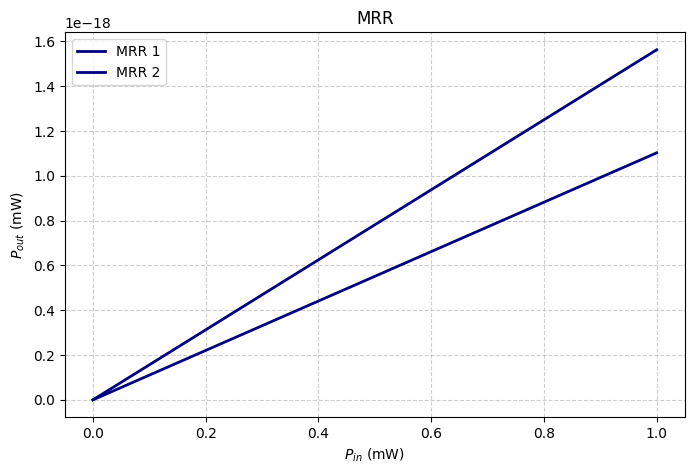

In [128]:
P_out_1 = P_out_vec_1
P_out_2 = P_out_vec_2
plt.figure(figsize=(8, 5))
plt.plot(P_in_vec, P_out_1, color='navy', linewidth=2, label='MRR 1')
plt.plot(P_in_vec, P_out_2, color='navy', linewidth=2, label='MRR 2')
plt.title('MRR')
plt.xlabel('$P_{in}$ (mW)')
plt.ylabel('$P_{out}$ (mW)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()